## Data Preprocessing Pipeline (Modified for Local Execution)

In [6]:
# Step 1: Load Data Locally (Google Colab removed for local run)
import pandas as pd
import numpy as np
import os

print("Loading local dataset...")
# Using the local dataset instead of Google Drive
df = pd.read_csv('dataset/train.csv')

# View the shape and first 4 rows
print("\nDataset Shape:", df.shape)
display(df.head(4))

Loading local dataset...

Dataset Shape: (45000, 15)


,Student_ID,Age,Gender,Degree,Branch,CGPA,Internships,Projects,Coding_Skills,Communication_Skills,Aptitude_Test_Score,Soft_Skills_Rating,Certifications,Backlogs,Placement_Status
0,1048,22,Female,B.Tech,ECE,6.29,0,3,4,6,51,5,1,3,Not Placed
1,37820,20,Female,BCA,ECE,6.05,1,4,6,8,59,8,2,1,Not Placed
2,49668,22,Male,MCA,ME,7.22,1,4,6,6,58,6,2,2,Not Placed
3,19467,22,Male,MCA,ME,7.78,2,4,6,6,90,4,2,0,Placed


In [ ]:
# Step 2: Find Null (Missing) Values
print("\nTotal missing values in entire dataset:", df.isnull().sum().sum())
print("\nMissing values per column:\n", df.isnull().sum())

# Calculate overall percentage of missing data
missing_percentage = (df.isnull().sum().sum() / (df.shape[0] * df.shape[1])) * 100
print(f"\nOverall dataset missing percentage: {missing_percentage:.2f}%")


Total missing values in entire dataset: 0

Missing values per column:
 Student_ID              0
Age                     0
Gender                  0
Degree                  0
Branch                  0
CGPA                    0
Internships             0
Projects                0
Coding_Skills           0
Communication_Skills    0
Aptitude_Test_Score     0
Soft_Skills_Rating      0
Certifications          0
Backlogs                0
Placement_Status        0
dtype: int64

Overall dataset missing percentage: 0.00%


: 


Generating Missing Values Heatmap...


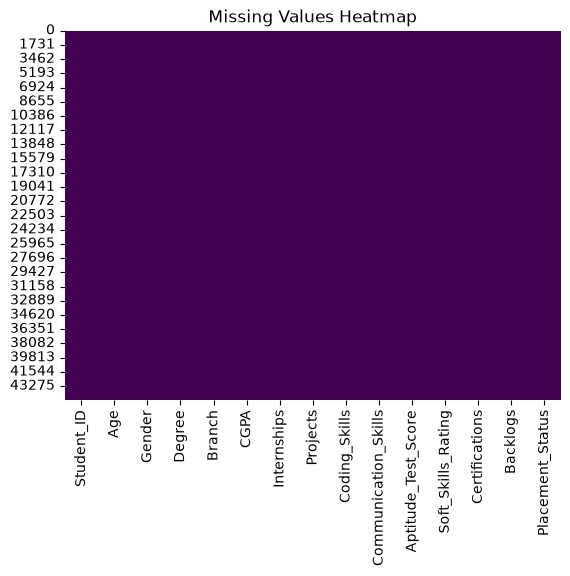

In [8]:
# Step 3: Graph Null Values (Heatmap)
import seaborn as sns
import matplotlib.pyplot as plt

print("\nGenerating Missing Values Heatmap...")
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title("Missing Values Heatmap")
plt.show()

In [9]:
# Step 4: Handle Missing Text Data (Categorical)
# Find all object (text) columns
object_cols = df.select_dtypes(include="object").columns
print("\nObject columns found:", object_cols.tolist())

# Fill missing spaces with the Mode
for col in object_cols:
    df[col].fillna(df[col].mode()[0], inplace=True)

print("Text columns successfully filled with Mode!")


Object columns found: ['Gender', 'Degree', 'Branch', 'Placement_Status']
Text columns successfully filled with Mode!


C:\Users\Pansh\AppData\Local\Temp\ipykernel_240\359445668.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  object_cols = df.select_dtypes(include="object").columns
C:\Users\Pansh\AppData\Local\Temp\ipykernel_240\359445668.py:8: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df

In [10]:
# Step 5: Handle Missing Numerical Data (Float)
from sklearn.impute import SimpleImputer

# Dynamically find all numerical columns (int64 and float64) in the actual dataset
num_cols = df.select_dtypes(include=["float64", "int64"]).columns
# Remove the target column if it exists so we don't impute the answer
if "Placement_Status" in num_cols:
    num_cols = num_cols.drop("Placement_Status")

print("\nNumerical columns found:", num_cols.tolist())

# Create the imputer to fill with the Mean
si = SimpleImputer(strategy="mean")

# Transform the data
ar = si.fit_transform(df[num_cols])

# Create a new cleaned dataset for the numerical columns
new_datset = pd.DataFrame(ar, columns=num_cols)

# Verify that there are no more missing values
print("\nRemaining null values in numerical columns:\n", new_datset.isnull().sum())

# Check the means of the first two numerical columns to verify
if len(num_cols) >= 2:
    col1 = num_cols[0]
    col2 = num_cols[1]
    print(f"\nMean of {col1}:", new_datset[col1].mean())
    print(f"Mean of {col2}:", new_datset[col2].mean())


Numerical columns found: ['Student_ID', 'Age', 'CGPA', 'Internships', 'Projects', 'Coding_Skills', 'Communication_Skills', 'Aptitude_Test_Score', 'Soft_Skills_Rating', 'Certifications', 'Backlogs']

Remaining null values in numerical columns:
 Student_ID              0
Age                     0
CGPA                    0
Internships             0
Projects                0
Coding_Skills           0
Communication_Skills    0
Aptitude_Test_Score     0
Soft_Skills_Rating      0
Certifications          0
Backlogs                0
dtype: int64

Mean of Student_ID: 24977.9626
Mean of Age: 20.999333333333333
